# 0. Setup


In [1]:
# Librerías
import pandas as pd
import matplotlib.pyplot as plt

# Configuración para ver más filas y columnas
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 100)

# Deshabilitar notación científica
pd.options.display.float_format = '{:.2f}'.format

def imprimir_tasa(tabla):
    # Las tasas se leen en porcentaje. El resto del notebook sigue en dos decimales.
    with pd.option_context('display.float_format', '{:.1%}'.format):
        print(tabla)


# 1. Entendimiento y preparación de los datos

En esta sección se revisan los datos tal como llega: tamaño, tipos, nulos y valores que no tienen sentido. Después se deja una versión limpia y se miran las distribuciones, sobre todo las que cambian la tasa de `churn`. La imputación de los nulos que sobrevivan a la limpieza no se hace aquí. La mediana tiene que salir solo del conjunto de entrenamiento, para no filtrar el test.


## 1.1. Carga y dimensiones


In [31]:
# Cargar datos
df = pd.read_csv("churn.csv")


In [32]:
# Explorar datos
df.head(n=15)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.00,France,Female,46.00,9,0.00,1,1,1,81014.50,1
1,689.00,Germany,Male,67.00,9,157094.78,1,1,1,99490.01,0
2,477.00,Spain,Female,48.00,2,129120.64,1,0,1,26475.79,0
3,573.00,Germany,Female,35.00,9,206868.78,2,0,1,102986.15,0
4,849.00,France,Male,69.00,7,71996.09,1,1,1,139065.94,0
5,796.00,France,Male,24.00,8,0.00,2,1,0,61349.37,0
6,497.00,Spain,Male,24.00,3,0.00,2,1,0,76390.01,0
7,675.00,France,Female,21.00,8,NaN,1,1,0,18203.00,0
8,636.00,Germany,Female,31.00,9,80844.69,2,1,1,74641.90,0
9,789.00,France,Female,NaN,8,66201.96,1,1,1,79458.12,0


In [33]:
# Dimensiones (filas, columnas)
df.shape


(10045, 11)

In [34]:
# Información de los datos
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  str    
 2   gender            10045 non-null  str    
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 863.4 KB


In [35]:
# Estadísticas descriptivas
df.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])


,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,9795.00,9745.00,10045.00,9845.00,10045.00,10045.00,10045.00,9695.00,10045.00
mean,650.69,38.94,5.02,76317.50,1.53,0.70,0.51,100069.01,0.20
std,97.09,10.73,2.90,62422.43,0.58,0.46,0.50,57510.69,0.40
min,95.00,-1.00,-2.00,0.00,1.00,0.00,0.00,-5000.00,0.00
1%,432.00,21.00,0.00,0.00,1.00,0.00,0.00,1787.11,0.00
5%,490.00,25.00,1.00,0.00,1.00,0.00,0.00,9984.24,0.00
25%,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51013.65,0.00
50%,652.00,37.00,5.00,97042.60,1.00,1.00,1.00,100130.95,0.00
75%,718.00,44.00,8.00,127559.97,2.00,1.00,1.00,149382.88,0.00
95%,813.00,60.00,9.00,162554.68,2.00,1.00,1.00,190170.51,1.00


El archivo trae **10,045 filas y 11 columnas**. Cada fila es un cliente. No existe un identificador, por lo que si hay dos filas iguales no hay forma de saber si son dos personas o la misma cargada dos veces.

`churn` es la etiqueta. Vale 1 si el cliente abandonó y 0 si se quedó. En crudo hay **2,045 abandonos (20.4%)**. El enunciado cita una tasa de deserción de la banca minorista cerca del **15%**. Esta muestra viene un poco más cargada de abandonos.


## 1.2. Tipos de variables

| Variable | Tipo | Qué representa | Rol |
|---|---|---|---|
| `credit_score` | numérica | puntaje crediticio | predictora |
| `country` | categórica | país del cliente | predictora |
| `gender` | categórica | sexo | predictora |
| `age` | numérica | edad en años | predictora |
| `tenure` | numérica discreta | años como cliente | predictora |
| `balance` | numérica | saldo de la cuenta | predictora |
| `products_number` | discreta (1 a 4) | cantidad de productos contratados | predictora |
| `credit_card` | binaria (0/1) | tiene tarjeta de crédito | predictora |
| `active_member` | binaria (0/1) | el cliente está activo | predictora |
| `estimated_salary` | numérica | salario estimado | predictora |
| `churn` | binaria (0/1) | abandonó | objetivo |

No hay fechas ni texto libre. `products_number` parece un conteo, pero la relación con el abandono no es lineal: se va a tratar como categoría cuando se arme el modelo. `credit_card` y `active_member` ya vienen en 0/1.


## 1.3. Calidad del registro


In [59]:
# Nulos por columna
nulos = df.isna().sum()
print(nulos)
print()
print("Filas con al menos un nulo:", int(df.isna().any(axis=1).sum()))
print("Filas con más de un nulo:", int((df.isna().sum(axis=1) > 1).sum()))
print("Duplicados exactos:", int(df.duplicated().sum()))


credit_score        250
country               0
gender                0
age                 300
tenure                0
balance             200
products_number       0
credit_card           0
active_member         0
estimated_salary    350
churn                 0
dtype: int64

Filas con al menos un nulo: 1100
Filas con más de un nulo: 0
Duplicados exactos: 45


In [60]:

# Etiquetas de país y de sexo, tal como vienen
print(df['country'].value_counts(dropna=False))
print([repr(x) for x in df['country'].unique()])
print()
print(df['gender'].value_counts(dropna=False))
print([repr(x) for x in df['gender'].unique()])


country
France      5003
Germany     2502
Spain       2475
FRANCE        22
france        17
GERMANY        9
SPAIN          9
germany        6
spain          2
Name: count, dtype: int64
["'France'", "'Germany'", "'Spain'", "'GERMANY'", "'FRANCE'", "'SPAIN'", "'spain '", "'france '", "'germany '"]

gender
Male      5464
Female    4551
M           16
F           14
Name: count, dtype: int64
["'Female'", "'Male'", "'F'", "'M'"]


In [61]:
# Valores que no caben en un cliente de banco
print("Edades fuera de [18, 100]:")
print(df.loc[~df['age'].between(18, 100) & df['age'].notna(), 'age'].sort_values().tolist())

print("Scores fuera de [300, 850]:")
print(df.loc[~df['credit_score'].between(300, 850) & df['credit_score'].notna(), 'credit_score'].sort_values().tolist())

print("Antigüedad fuera de [0, 10]:")
print(df.loc[~df['tenure'].between(0, 10), 'tenure'].sort_values().tolist())

print("Salarios negativos:")
print(df.loc[df['estimated_salary'] < 0, 'estimated_salary'].sort_values().tolist())

print("Saldos negativos:", int((df['balance'] < 0).sum()))
print("Saldos en cero:", int((df['balance'] == 0).sum()))


Edades fuera de [18, 100]:
[-1.0, 0.0, 5.0, 130.0, 150.0, 210.0]
Scores fuera de [300, 850]:
[95.0, 120.0, 999.0, 1200.0]
Antigüedad fuera de [0, 10]:
[-2, 15, 25]
Salarios negativos:
[-5000.0, -120.5, -1.0]
Saldos negativos: 0
Saldos en cero: 3574


Lo que se ve en el archivo, antes de tocar nada:

- **Nulos.** `estimated_salary` 350, `age` 300, `credit_score` 250, `balance` 200. Son **1,100 filas (11.0%)** y ninguna tiene más de un campo vacío. El resto de columnas viene completo, incluida `churn`.
- **Duplicados.** Hay **45 filas repetidas** exactas (90 filas que forman pareja). Sin un id no se puede rescatar la segunda copia: si se quedan, el mismo cliente puede caer en entrenamiento y en prueba.
- **País.** El grueso es France, Germany y Spain, pero **65 filas** llegan como `FRANCE`, `france `, `GERMANY`, `germany `, `SPAIN` o `spain ` (mayúsculas o espacio al final). Es el mismo país escrito distinto.
- **Sexo.** `Male` y `Female`, más **30 filas** en `M` y `F`.
- **Valores imposibles**, pocos pero claros:
  - edad: `-1`, `0`, `5`, `130`, `150`, `210`
  - score: `95`, `120`, `999`, `1200`
  - antigüedad: `-2`, `15`, `25` (el resto de la muestra es un entero de 0 a 10)
  - salario: `-5000`, `-120.50`, `-1`
- **El saldo en cero no es un error.** Hay 3,574 ceros en el crudo y ningún saldo negativo. Se conservan.

Suponemos que un experto del negocio confirmaría estos rangos: cliente adulto de 18 a 100 años, score comercial entre 300 y 850 (850 es un techo que sí se repite en la muestra), antigüedad de 0 a 10 años y salario que no puede ser negativo.


## 1.4. Preparación

Reglas, en este orden:

1. Se eliminan los 45 duplicados exactos. Quedan 10,000 clientes.
2. `country` se recorta y se pasa a título (`France`, `Germany`, `Spain`).
3. `F` y `M` se unifican con `Female` y `Male`.
4. Los valores imposibles de edad, score, antigüedad y salario se anulan. La fila se conserva: el resto de atributos sigue siendo útil. Mismo criterio que usaríamos con un dato mal digitado y no con un cliente que no existe.
5. El saldo 0 se deja.
6. No se imputa todavía. Tras anular los imposibles, los nulos siguen siendo un solo campo por fila y la tasa de `churn` de esas filas es parecida a la global, así que el hueco no parece ser otra forma de la etiqueta. La mediana se calcula en el entrenamiento, solo con train.


In [62]:
df_limpio = df.copy()

# 1. Duplicados exactos
df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

# 2 y 3. Etiquetas
df_limpio['country'] = df_limpio['country'].str.strip().str.title()
df_limpio['gender'] = df_limpio['gender'].replace({'F': 'Female', 'M': 'Male'})

# 4. Valores imposibles -> nulo. No se borra la fila.
edad_invalida = ~df_limpio['age'].between(18, 100) & df_limpio['age'].notna()
score_invalido = ~df_limpio['credit_score'].between(300, 850) & df_limpio['credit_score'].notna()
tenure_invalida = ~df_limpio['tenure'].between(0, 10)
salario_invalido = df_limpio['estimated_salary'] < 0

df_limpio.loc[edad_invalida, 'age'] = pd.NA
df_limpio.loc[score_invalido, 'credit_score'] = pd.NA
df_limpio.loc[tenure_invalida, 'tenure'] = pd.NA
df_limpio.loc[salario_invalido, 'estimated_salary'] = pd.NA

print("Filas:", df_limpio.shape[0])
print("País:", df_limpio['country'].value_counts().to_dict())
print("Sexo:", df_limpio['gender'].value_counts().to_dict())
print()
print("Nulos después de anular imposibles:")
print(df_limpio.isna().sum())
print()
print("Filas con algún nulo:", int(df_limpio.isna().any(axis=1).sum()))
print("Churn en filas con nulo:", df_limpio.loc[df_limpio.isna().any(axis=1), 'churn'].mean())
print("Churn en filas completas:", df_limpio.dropna().churn.mean())
print("Churn global:", df_limpio['churn'].mean(), "abandonos:", int(df_limpio['churn'].sum()))


Filas: 10000
País: {'France': 5014, 'Germany': 2509, 'Spain': 2477}
Sexo: {'Male': 5457, 'Female': 4543}

Nulos después de anular imposibles:
credit_score        254
country               0
gender                0
age                 306
tenure                3
balance             200
products_number       0
credit_card           0
active_member         0
estimated_salary    353
churn                 0
dtype: int64

Filas con algún nulo: 1116
Churn en filas con nulo: 0.19265232974910393
Churn en filas completas: 0.205087798289059
Churn global: 0.2037 abandonos: 2037


Quedan **10,000 clientes** y **2,037 abandonos (20.4%)**. País y sexo quedan en tres y dos categorías. Los nulos suben un poco, porque los imposibles ahora también son nulos: salario 353, edad 306, score 254, saldo 200, antigüedad 3. Son **1,116 filas (11.2%)**. Su tasa de abandono es **19.3%**, contra **20.5%** en las filas completas. Cercanas. No vamos a botar el 11% de la muestra por un solo campo.

Los gráficos de aquí en adelante usan `df_limpio`.


## 1.5. Variable objetivo: `churn`


churn
0    7963
1    2037
Name: count, dtype: int64

churn
0   79.6%
1   20.4%
Name: proportion, dtype: float64


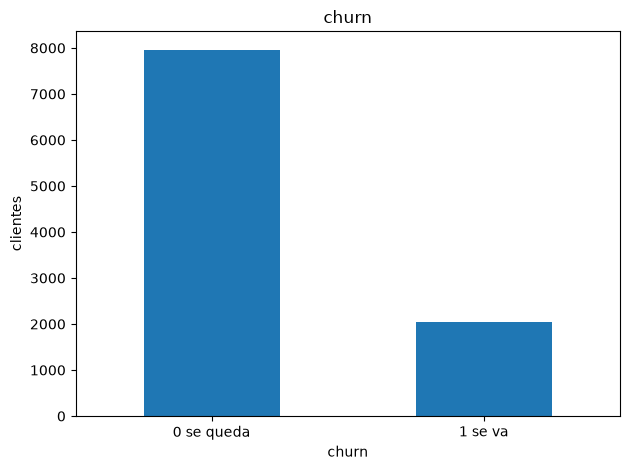

In [40]:

print(df_limpio['churn'].value_counts().sort_index())
print()
imprimir_tasa(df_limpio['churn'].value_counts(normalize=True).sort_index())

df_limpio['churn'].value_counts().sort_index().plot(kind='bar')
plt.xticks([0, 1], ['0 se queda', '1 se va'], rotation=0)
plt.xlabel('churn')
plt.ylabel('clientes')
plt.title('churn')
plt.tight_layout()
plt.show()


`churn` está desbalanceada, sin nulos: **79.6% se quedan y 20.4% se van**.

Para el modelo, accuracy sola va a verse bien aunque el clasificador diga siempre "se queda" (acertaría ~80% y no encontraría a nadie). Las métricas que le importan a FinAlpes son las que miran a la clase 1: a quién se contacta y a cuántos de los que sí se iban se alcanza a tocar. Eso se retoma en la evaluación.

La línea base de negocio del enunciado es ~15%. Acá el evento es más frecuente. Al pasar el modelo a un banco de 20,000 clientes hay que volver a estimar la tasa, no heredar este 20.4%.


## 1.6. Atributos que consideramos más importantes

El objetivo de negocio es priorizar a quién ofrecerle una campaña de retención. Una variable sirve si mueve la tasa de abandono respecto al 20.4% global, y si el movimiento es interpretable.

El orden de abajo es el de la señal, no el del archivo. `products_number` casi no correlaciona en lineal y aun así es de las más útiles: la relación no es una recta. Por eso no se descarta nada solo con la correlación.


### 1.6.1. Edad

Variable **numérica**. En crudo el mínimo es -1 y el máximo 210, y eso infla la kurtosis. Ya anulamos esos seis valores. El análisis es sobre la edad válida.


In [63]:
print(df_limpio['age'].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))
print("Sesgo:", df_limpio['age'].skew())
print("Kurtosis:", df_limpio['age'].kurtosis())
print("Nulos:", int(df_limpio['age'].isna().sum()))
print()
print(df_limpio.groupby('churn')['age'].agg(['count', 'mean', 'median']))


count   9694.00
mean      38.92
std       10.47
min       18.00
1%        21.00
5%        25.00
25%       32.00
50%       37.00
75%       44.00
95%       60.00
99%       72.00
max       92.00
Name: age, dtype: float64
Sesgo: 0.9960784706688375
Kurtosis: 1.3249883233666815
Nulos: 306

       count  mean  median
churn                     
0       7709 37.41   36.00
1       1985 44.77   45.00


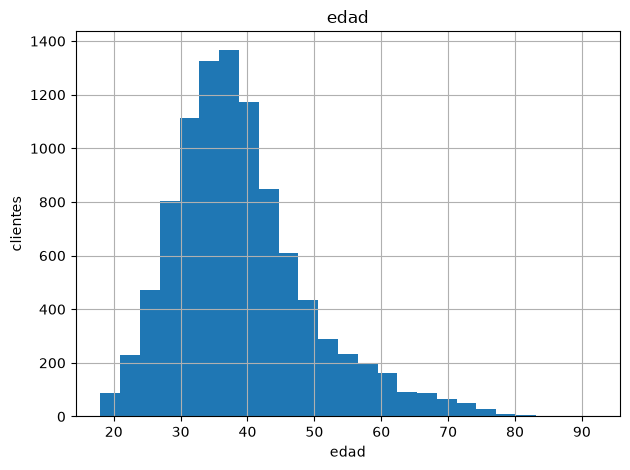

In [42]:
df_limpio['age'].hist(bins=25)
plt.xlabel('edad')
plt.ylabel('clientes')
plt.title('edad')
plt.tight_layout()
plt.show()


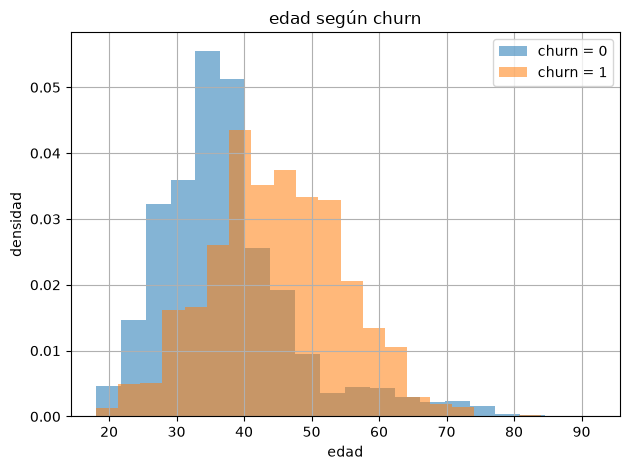

In [43]:
df_limpio.loc[df_limpio['churn'] == 0, 'age'].hist(bins=20, density=True, alpha=0.55, label='churn = 0')
df_limpio.loc[df_limpio['churn'] == 1, 'age'].hist(bins=20, density=True, alpha=0.55, label='churn = 1')
plt.xlabel('edad')
plt.ylabel('densidad')
plt.title('edad según churn')
plt.legend()
plt.tight_layout()
plt.show()


       count  mean
age               
18-30   1910  7.7%
31-40   4304 12.3%
41-50   2252 33.8%
51-60    782 56.0%
61+      446 24.7%


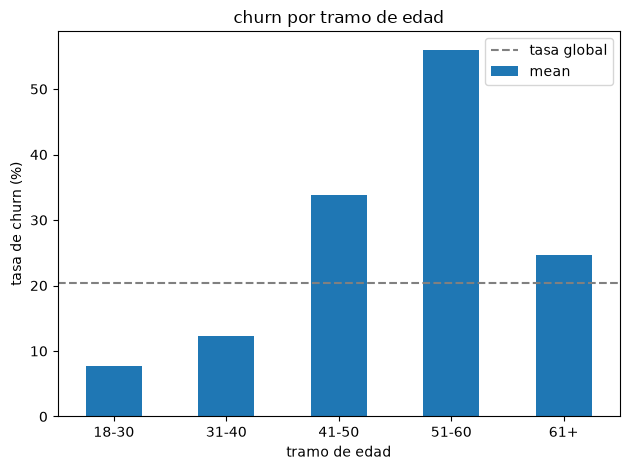

In [44]:

tramo_edad = pd.cut(
    df_limpio['age'],
    bins=[17, 30, 40, 50, 60, 100],
    labels=['18-30', '31-40', '41-50', '51-60', '61+'],
)

tasa_edad = df_limpio.groupby(tramo_edad, observed=False)['churn'].agg(['count', 'mean'])
imprimir_tasa(tasa_edad)

(tasa_edad['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('tramo de edad')
plt.ylabel('tasa de churn (%)')
plt.title('churn por tramo de edad')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


La edad **sí separa**, y no de forma pareja.

- Mediana **37 años**. Sesgo ~1.0: cola hacia los mayores, ya sin el 210. Kurtosis ~1.3.
- Quien se queda tiene mediana **36**. Quien se va, mediana **45**. Nueve años de diferencia.
- La tasa por tramo: **18-30 → 7.7%** (1,910), **31-40 → 12.3%** (4,304), **41-50 → 33.8%** (2,252), **51-60 → 56.0%** (782), **61+ → 24.7%** (446).
- El tramo de 51 a 60 es el más chico de los de abajo de 60 y el de mayor riesgo: más de la mitad se va. Después de 60 la tasa baja. Una recta (más edad, más abandono) se equivoca en los mayores.
- Para la campaña, la edad entra mejor en tramos que como un solo coeficiente. Los nulos (306) se imputan en train.


### 1.6.2. País


country
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

country
France    50.1%
Germany   25.1%
Spain     24.8%
Name: proportion, dtype: float64
Nulos: 0


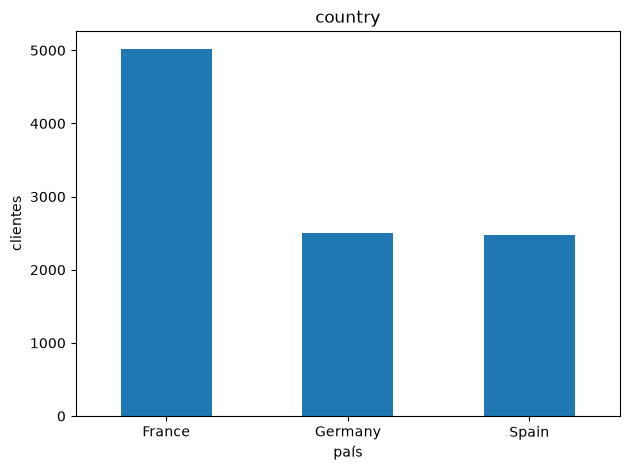

In [45]:

print(df_limpio['country'].value_counts(dropna=False))
print()
imprimir_tasa(df_limpio['country'].value_counts(normalize=True))
print("Nulos:", int(df_limpio['country'].isna().sum()))

df_limpio['country'].value_counts().plot(kind='bar')
plt.xlabel('país')
plt.ylabel('clientes')
plt.title('country')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


         count  sum  mean
country                  
Germany   2509  814 32.4%
Spain     2477  413 16.7%
France    5014  810 16.2%


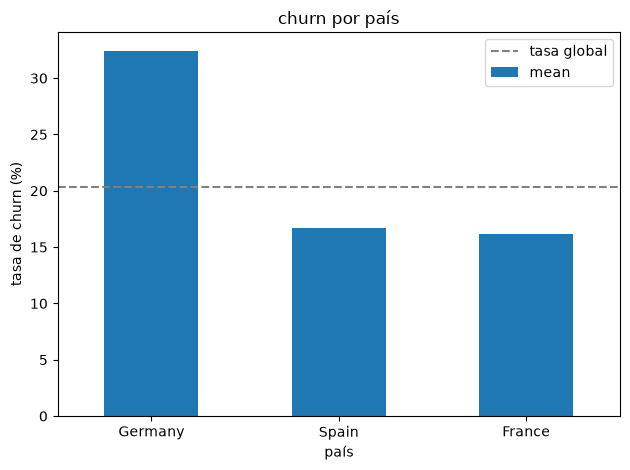

In [46]:

tasa_pais = df_limpio.groupby('country')['churn'].agg(['count', 'sum', 'mean']).sort_values('mean', ascending=False)
imprimir_tasa(tasa_pais)

(tasa_pais['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('país')
plt.ylabel('tasa de churn (%)')
plt.title('churn por país')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


`country` queda en **3 categorías**, sin nulos. La mitad de la muestra es Francia.

- France **5,014 (50.1%)**, tasa **16.2%** (810 abandonos).
- Spain **2,477 (24.8%)**, tasa **16.7%** (413).
- Germany **2,509 (25.1%)**, tasa **32.4%** (814).

Alemania es un cuarto de los clientes y **814 de los 2,037 abandonos (40.0%)**: casi los mismos que Francia, con la mitad de gente. Francia y España se parecen. El país entra como categoría. No hay un orden entre los tres.


### 1.6.3. Número de productos

Variable **discreta**, de 1 a 4. Se mira como categoría: el paso de 1 a 2 no se parece al paso de 2 a 3.


products_number
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

products_number
1   50.8%
2   45.9%
3    2.7%
4    0.6%
Name: proportion, dtype: float64
                 count   sum   mean
products_number                    
1                 5084  1409  27.7%
2                 4590   348   7.6%
3                  266   220  82.7%
4                   60    60 100.0%


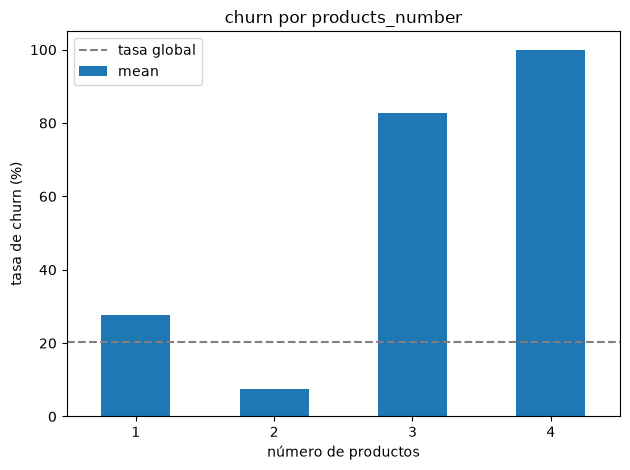

In [47]:

print(df_limpio['products_number'].value_counts().sort_index())
print()
imprimir_tasa(df_limpio['products_number'].value_counts(normalize=True).sort_index())

tasa_prod = df_limpio.groupby('products_number')['churn'].agg(['count', 'sum', 'mean'])
imprimir_tasa(tasa_prod)

(tasa_prod['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('número de productos')
plt.ylabel('tasa de churn (%)')
plt.title('churn por products_number')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [48]:

# Cruce con actividad: el caso de un solo producto inactivo concentra abandono
cruce_tasa = df_limpio.pivot_table(
    index='products_number',
    columns='active_member',
    values='churn',
    aggfunc='mean',
)
cruce_n = df_limpio.pivot_table(
    index='products_number',
    columns='active_member',
    values='churn',
    aggfunc='count',
)
print('Tasa')
imprimir_tasa(cruce_tasa)
print()
print('Clientes')
print(cruce_n)


Tasa
active_member        0      1
products_number              
1                36.7%  18.9%
2                 9.9%   5.6%
3                88.2%  75.2%
4               100.0% 100.0%

Clientes
active_member       0     1
products_number            
1                2521  2563
2                2144  2446
3                 153   113
4                  31    29


`products_number` es de las señales más fuertes, y es **no lineal**.

- **1 producto:** 5,084 clientes (50.8%), tasa **27.7%**. Aportan **1,409 de 2,037 abandonos (69.2%)**.
- **2 productos:** 4,590 (45.9%), tasa **7.6%**. Es el grupo que se queda.
- **3 productos:** 266 (2.7%), tasa **82.7%**.
- **4 productos:** 60 (0.6%), tasa **100%** (60 de 60). Son pocos; la tasa perfecta no se puede leer como una ley, pero el grupo sí es de riesgo alto.
- Juntos, 3 y 4 productos son **326 clientes (3.3% de la base) y 280 abandonos**.

El cliente con dos productos es el de menor riesgo. El de uno solo ya está por encima del promedio, y con tres o cuatro el abandono es la norma. Meter esta variable como número en una regresión lineal le asignaría un solo signo y se come justo este quiebre. En el modelo va como categoría.

El cruce con actividad refuerza el foco: **un producto e inactivo** está en **36.7%** de abandono (2,521 clientes). Dos productos, activo o no, se mantiene bajo.


### 1.6.4. Cliente activo


active_member
0    4849
1    5151
Name: count, dtype: int64

               count   sum  mean
active_member                   
0               4849  1302 26.9%
1               5151   735 14.3%


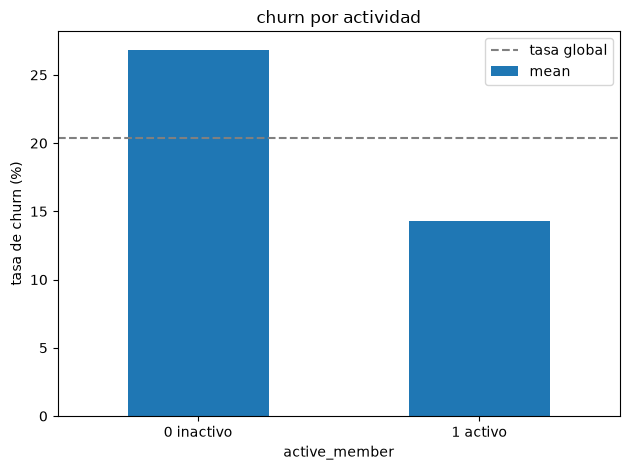

In [49]:

print(df_limpio['active_member'].value_counts().sort_index())
print()
tasa_activo = df_limpio.groupby('active_member')['churn'].agg(['count', 'sum', 'mean'])
imprimir_tasa(tasa_activo)

(tasa_activo['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xticks([0, 1], ['0 inactivo', '1 activo'], rotation=0)
plt.xlabel('active_member')
plt.ylabel('tasa de churn (%)')
plt.title('churn por actividad')
plt.legend()
plt.tight_layout()
plt.show()


`active_member` es binaria, sin nulos, partida casi a la mitad.

- Inactivo: **4,849** clientes, tasa **26.9%**, **1,302 abandonos (63.9% de todos los que se van)**.
- Activo: **5,151** clientes, tasa **14.3%**.

El inactivo abandona casi al doble. Es un criterio directo para la campaña: si hay que ordenar a quién llamar, el inactivo va antes que el activo, en igualdad del resto. No dice por qué está inactivo (puede ser que ya se estaba yendo). Es asociación, no causa.


### 1.6.5. Sexo


gender
Male      5457
Female    4543
Name: count, dtype: int64

        count   sum  mean
gender                   
Female   4543  1139 25.1%
Male     5457   898 16.5%

Tasa por país y sexo
gender   Female  Male
country              
France    20.3% 12.7%
Germany   37.6% 27.8%
Spain     21.2% 13.1%
Clientes
gender   Female  Male
country              
France     2261  2753
Germany    1193  1316
Spain      1089  1388


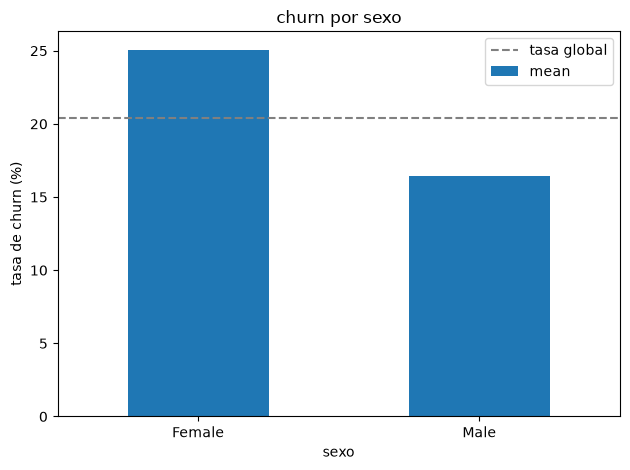

In [50]:

print(df_limpio['gender'].value_counts())
print()
tasa_sexo = df_limpio.groupby('gender')['churn'].agg(['count', 'sum', 'mean'])
imprimir_tasa(tasa_sexo)

print()
print('Tasa por país y sexo')
imprimir_tasa(df_limpio.pivot_table(index='country', columns='gender', values='churn', aggfunc='mean'))
print('Clientes')
print(df_limpio.pivot_table(index='country', columns='gender', values='churn', aggfunc='count'))

(tasa_sexo['mean'] * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xlabel('sexo')
plt.ylabel('tasa de churn (%)')
plt.title('churn por sexo')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


`gender` queda en dos categorías, sin nulos.

- Female: **4,543 (45.4%)**, tasa **25.1%**, **1,139 abandonos**.
- Male: **5,457 (54.6%)**, tasa **16.5%**, **898 abandonos**.

Las mujeres son menos de la mitad de la base y más de la mitad de los abandonos. La brecha se mantiene dentro de cada país. El caso más alto del cruce es **mujer en Alemania (37.6%)**; el más bajo, **hombre en Francia (12.7%)**. El sexo entra como categoría. No alcanza para definir la campaña solo, y se usa junto con país, productos y actividad.


### 1.6.6. Saldo

Variable **numérica**, con una masa grande en cero. El cero se conserva: es un estado de la cuenta, no un dato faltante. Los 200 nulos de `balance` sí son huecos y no se mezclan con el cero.


In [51]:

print(df_limpio['balance'].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))
print('Sesgo:', df_limpio['balance'].skew())
print('Kurtosis:', df_limpio['balance'].kurtosis())
print('Ceros:', int((df_limpio['balance'] == 0).sum()))
print('Proporción de ceros sobre filas:', f"{(df_limpio['balance'] == 0).mean():.1%}")
print('Proporción de ceros sobre saldos conocidos:', f"{(df_limpio['balance'] == 0).sum() / df_limpio['balance'].notna().sum():.1%}")
print('Nulos:', int(df_limpio['balance'].isna().sum()))
print()
print('Ceros por país (sobre saldos conocidos):')
imprimir_tasa(
    df_limpio.groupby('country')['balance'].apply(lambda s: (s == 0).sum() / s.notna().sum())
)


count     9800.00
mean     76286.25
std      62413.45
min          0.00
1%           0.00
5%           0.00
25%          0.00
50%      97038.69
75%     127537.15
95%     162488.12
99%     186103.65
max     250898.09
Name: balance, dtype: float64
Sesgo: -0.13653786331635326
Kurtosis: -1.4927656007606487
Ceros: 3559
Proporción de ceros sobre filas: 35.6%
Proporción de ceros sobre saldos conocidos: 36.3%
Nulos: 200

Ceros por país (sobre saldos conocidos):
country
France    48.4%
Germany    0.0%
Spain     48.7%
Name: balance, dtype: float64


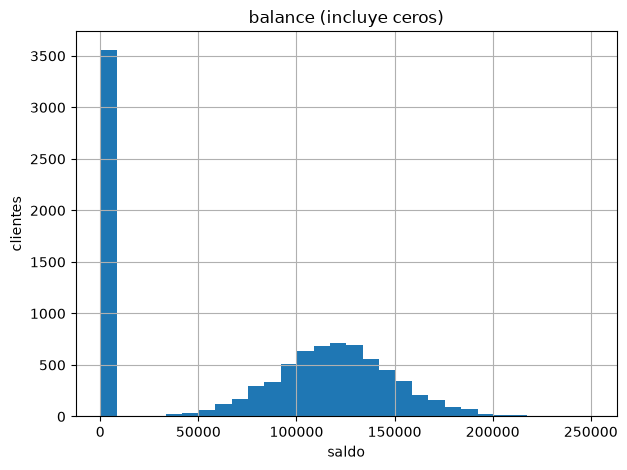

In [52]:
df_limpio['balance'].hist(bins=30)
plt.xlabel('saldo')
plt.ylabel('clientes')
plt.title('balance (incluye ceros)')
plt.tight_layout()
plt.show()


count     6241.00
mean    119789.34
std      30086.06
min       3768.69
5%       70362.52
25%     100212.13
50%     119825.75
75%     139301.68
95%     169902.92
max     250898.09
Name: balance, dtype: float64
Sesgo: 0.022589246099987047
Kurtosis: 0.2141158035625979

       count    median      mean
churn                           
0       4734 119796.97 119514.96
1       1507 119852.01 120651.26


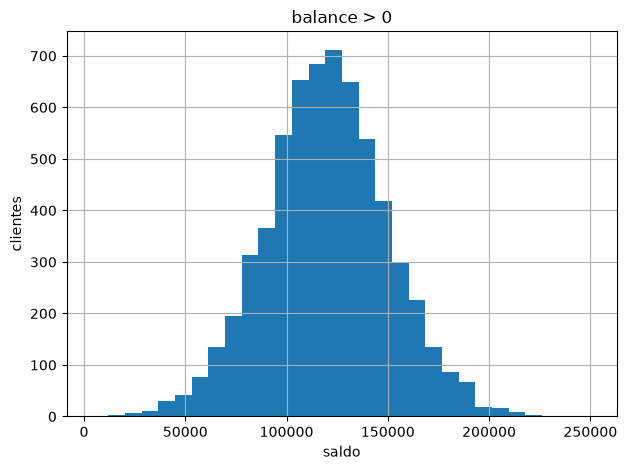

In [53]:
# Sin el cero, para ver la forma del saldo de quien sí tiene plata en la cuenta
saldo_positivo = df_limpio.loc[df_limpio['balance'] > 0, 'balance']
print(saldo_positivo.describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]))
print("Sesgo:", saldo_positivo.skew())
print("Kurtosis:", saldo_positivo.kurtosis())
print()
print(df_limpio.loc[df_limpio['balance'] > 0].groupby('churn')['balance'].agg(['count', 'median', 'mean']))

saldo_positivo.hist(bins=30)
plt.xlabel('saldo')
plt.ylabel('clientes')
plt.title('balance > 0')
plt.tight_layout()
plt.show()


In [54]:

# Los nulos de balance no entran en este corte, para no mezclarlos con el cero
con_saldo_conocido = df_limpio.loc[df_limpio['balance'].notna()].copy()
con_saldo_conocido['tiene_saldo'] = con_saldo_conocido['balance'].gt(0).map({True: 'con saldo', False: 'saldo 0'})
tasa_saldo = con_saldo_conocido.groupby(['country', 'tiene_saldo'])['churn'].agg(['count', 'mean'])
imprimir_tasa(tasa_saldo)


                     count  mean
country tiene_saldo             
France  con saldo     2536 18.3%
        saldo 0       2375 14.0%
Germany con saldo     2456 32.5%
Spain   con saldo     1249 19.5%
        saldo 0       1184 13.8%


El histograma crudo no es una campana. **3,559 clientes tienen saldo 0** (36.3% de los saldos conocidos). Sesgo -0.14 y kurtosis -1.49: la masa en cero aplana la distribución y baja la media (**76,286**) por debajo de la mediana (**97,039**).

Alemania tiene **cero clientes con saldo 0**. Francia está en **48.4%** y España en **48.7%**, sobre los saldos conocidos.

Si se mira solo a quien tiene saldo positivo (6,241 clientes), el monto ya sí es simétrico: mediana **~119,800**, sesgo ~0.02. Y **deja de separar el abandono**: mediana 119,797 si se queda y 119,852 si se va.

La tasa, partida por país:

- Francia, saldo 0: **14.0%**. Francia, con saldo: **18.3%**.
- España, saldo 0: **13.8%**. España, con saldo: **19.5%**.
- Alemania no tiene ceros. Con saldo informado: **32.5%**.

El monto del saldo, entre quienes lo tienen, no dice quién se va. Lo que sí se ve es el **estado** saldo = 0, y está mezclado con el país: Alemania no tiene ceros y es el país de mayor abandono. Por eso un modelo que use `balance` como número continuo se puede quedar con el efecto de Alemania. Conviene llevar el cero como indicador propio y no borrar esos registros. Los 200 nulos se imputan en train; no se rellenan con cero.


## 1.7. Variables que casi no separan

`credit_score`, `tenure`, `estimated_salary` y `credit_card` se revisan igual, para no dejarlas fuera del reporte. La conclusión es que mueven poco la tasa.


In [55]:
for col in ['credit_score', 'tenure', 'estimated_salary']:
    print("=" * 60)
    print(col)
    print(df_limpio[col].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))
    print("Sesgo:", df_limpio[col].skew())
    print("Kurtosis:", df_limpio[col].kurtosis())
    print("Nulos:", int(df_limpio[col].isna().sum()))
    print(df_limpio.groupby('churn')[col].agg(['count', 'median', 'mean']))
    print()


credit_score
count   9746.00
mean     650.62
std       96.62
min      350.00
1%       432.00
5%       490.00
25%      584.00
50%      652.00
75%      718.00
95%      812.00
99%      850.00
max      850.00
Name: credit_score, dtype: float64
Sesgo: -0.06760008899391173
Kurtosis: -0.43825532377249893
Nulos: 254
       count  median   mean
churn                      
0       7769  654.00 651.98
1       1977  646.00 645.31

tenure
count   9997.00
mean       5.01
std        2.89
min        0.00
1%         0.00
5%         1.00
25%        3.00
50%        5.00
75%        7.00
95%        9.00
99%       10.00
max       10.00
Name: tenure, dtype: float64
Sesgo: 0.01044828090237175
Kurtosis: -1.1648933831919532
Nulos: 3
       count  median  mean
churn                     
0       7960    5.00  5.03
1       2037    5.00  4.93

estimated_salary
count     9647.00
mean    100069.67
std      57484.03
min         11.58
1%        1798.62
5%        9991.68
25%      51106.18
50%     100137.70
75%     14937

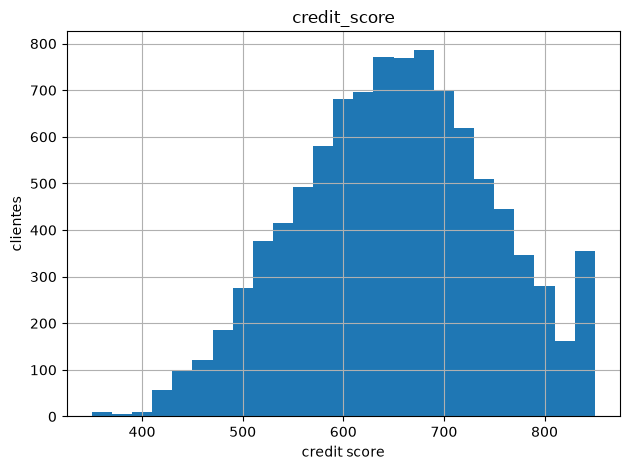

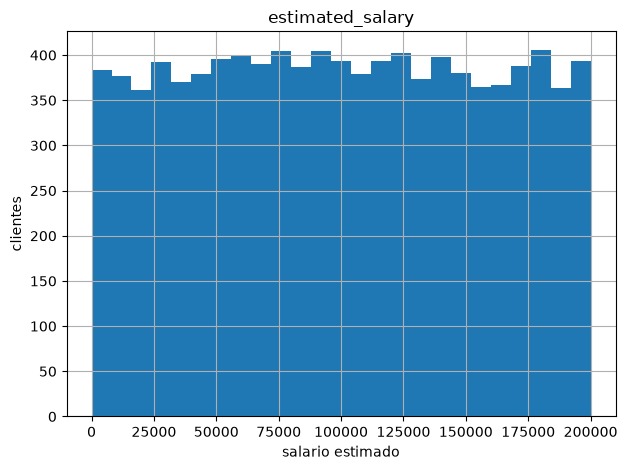

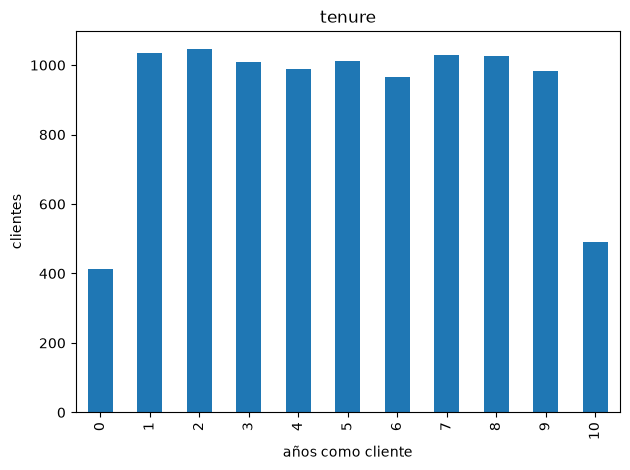

In [56]:
df_limpio['credit_score'].hist(bins=25)
plt.xlabel('credit score')
plt.ylabel('clientes')
plt.title('credit_score')
plt.tight_layout()
plt.show()

df_limpio['estimated_salary'].hist(bins=25)
plt.xlabel('salario estimado')
plt.ylabel('clientes')
plt.title('estimated_salary')
plt.tight_layout()
plt.show()

df_limpio['tenure'].dropna().astype(int).value_counts().sort_index().plot(kind='bar')
plt.xlabel('años como cliente')
plt.ylabel('clientes')
plt.title('tenure')
plt.tight_layout()
plt.show()


        count  mean
tenure             
0         413 23.0%
1        1034 22.4%
2        1046 19.2%
3        1009 21.1%
4         989 20.5%
5        1012 20.7%
6         967 20.3%
7        1028 17.2%
8        1025 19.2%
9         984 21.6%
10        490 20.6%

             count   sum  mean
credit_card                   
0             2945   613 20.8%
1             7055  1424 20.2%


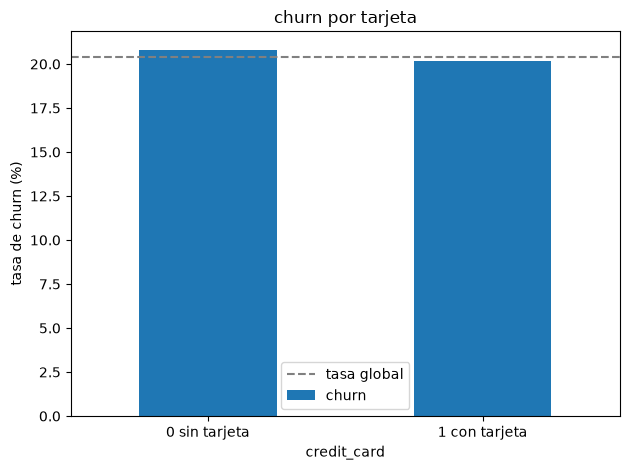

In [57]:

tasa_tenure = df_limpio.groupby('tenure', dropna=True)['churn'].agg(['count', 'mean'])
tasa_tenure.index = tasa_tenure.index.astype(int)
imprimir_tasa(tasa_tenure)
print()
imprimir_tasa(df_limpio.groupby('credit_card')['churn'].agg(['count', 'sum', 'mean']))

(df_limpio.groupby('credit_card')['churn'].mean() * 100).plot(kind='bar')
plt.axhline(df_limpio['churn'].mean() * 100, color='gray', linestyle='--', label='tasa global')
plt.xticks([0, 1], ['0 sin tarjeta', '1 con tarjeta'], rotation=0)
plt.xlabel('credit_card')
plt.ylabel('tasa de churn (%)')
plt.title('churn por tarjeta')
plt.legend()
plt.tight_layout()
plt.show()


- **`credit_score`.** Después de anular 95, 120, 999 y 1200, el rango válido es 350 a 850. Mediana **652**, sesgo ~0. La mediana de quien se va es **646** y la de quien se queda **654**. Ocho puntos, sobre una escala de 500. Se conserva, con señal débil. 254 nulos, a imputar en train.
- **`tenure`.** Enteros de 0 a 10, bastante parejos entre 1 y 9, con menos gente en 0 (413) y en 10 (490). La tasa se mueve entre **17% y 23%**, sin una tendencia clara con los años. Los tres valores raros (-2, 15, 25) ya quedaron nulos.
- **`estimated_salary`.** Casi uniforme entre ~12 y 200,000: sesgo ~0 y kurtosis ~-1.2 (más plana que una normal). Mediana **99,654** si se queda y **102,127** si se va. No alcanza para priorizar. Los negativos ya se anularon; quedan 353 nulos.
- **`credit_card`.** **7,055** clientes (70.6%) tienen tarjeta. Tasa **20.2%** con tarjeta y **20.8%** sin tarjeta. Prácticamente la tasa global. Se deja en el archivo porque viene completa y es barata de incluir; no es un criterio de focalización.


## 1.8. Qué singifica esto para el modelo

In [58]:
# Correlación lineal con churn. products_number sale cerca de cero y aun así es útil: la relación no es una recta.
columnas = [
    'credit_score', 'age', 'tenure', 'balance', 'products_number',
    'credit_card', 'active_member', 'estimated_salary', 'churn',
]
print(df_limpio[columnas].corr(numeric_only=True)['churn'].sort_values())


active_member      -0.16
products_number    -0.05
credit_score       -0.03
tenure             -0.01
credit_card        -0.01
estimated_salary    0.01
balance             0.12
age                 0.28
churn               1.00
Name: churn, dtype: float64


La correlación lineal ordena bien edad (positiva), actividad (negativa) y saldo (positiva, por los ceros y por Alemania). Deja a `products_number` cerca de cero. Esa correlación no se usa para botar variables.

| Variable | Señal | Cómo entra |
|---|---|---|
| `age` | Fuerte y no lineal. Pico en 51-60 (56%), baja después de 60 | Numérica, con opción de tramos. Nulos: mediana de train |
| `country` | Alemania 32.4% contra ~16% en Francia y España. 40% de los abandonos | Categórica |
| `products_number` | 2 productos protege (7.6%). 1 está en 27.7%. 3 y 4 están por encima de 80% | Categórica, no como número lineal |
| `active_member` | Inactivo 26.9% contra activo 14.3%. 64% de los abandonos | Binaria |
| `gender` | Mujer 25.1% contra hombre 16.5%. Se sostiene dentro de cada país | Categórica |
| `balance` | El monto, si es > 0, no separa. El cero sí, y Alemania no tiene ceros | Conservar el 0. No imputar ceros. Nulos: mediana de train |
| `credit_score` | Mediana 646 contra 654 | Se conserva. Señal débil |
| `tenure` | Tasa plana, entre 17% y 23% | Se conserva. Señal débil |
| `estimated_salary` | Casi uniforme. Medianas 99.7 mil contra 102 mil | Se conserva. Señal débil |
| `credit_card` | 20.2% contra 20.8% | Se conserva. Casi no separa |

`df_limpio` es el que sigue: 10,000 filas, etiquetas unificadas, duplicados fuera, imposibles en nulo. No está imputado ni codificado. Eso se hace al partir train y test, para que el ajuste no vea el conjunto de prueba.

Para focalizar, antes incluso del modelo, los grupos que más se despegan del 20.4% son: **51-60 años**, **Alemania**, **3 o 4 productos**, **un solo producto e inactivo**, y **mujer**. Dos productos es el grupo que menos se va.
